In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline as SklearnPipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
    confusion_matrix,
    classification_report,
    average_precision_score,
    precision_recall_curve
)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42

In [2]:
df = pd.read_csv("creditcard.csv")

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset shape: (284807, 31)

First five rows:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21 

In [3]:
print(df["Class"].value_counts())

Class
0    284315
1       492
Name: count, dtype: int64


In [4]:
class_counts = df["Class"].value_counts().sort_index()
class_percentages = df["Class"].value_counts(normalize=True).sort_index() * 100

imbalance_summary = pd.DataFrame({
    "Transaction Type": ["Legitimate", "Fraudulent"],
    "Count": [
        class_counts.get(0, 0),
        class_counts.get(1, 0)
    ],
    "Percentage": [
        class_percentages.get(0, 0),
        class_percentages.get(1, 0)
    ]
})

display(imbalance_summary.round(4))

fraud_percentage = (df["Class"] == 1).mean() * 100
print(f"Fraud percentage: {fraud_percentage:.4f}%")

,Transaction Type,Count,Percentage
0,Legitimate,284315,99.8273
1,Fraudulent,492,0.1727


Fraud percentage: 0.1727%


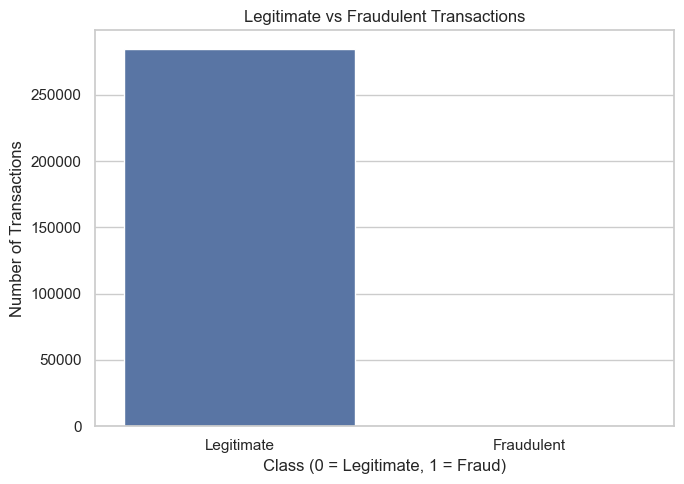

In [5]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Class", hue="Class", legend=False)

plt.title("Legitimate vs Fraudulent Transactions")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("Number of Transactions")
plt.xticks([0, 1], ["Legitimate", "Fraudulent"])
plt.tight_layout()
plt.show()

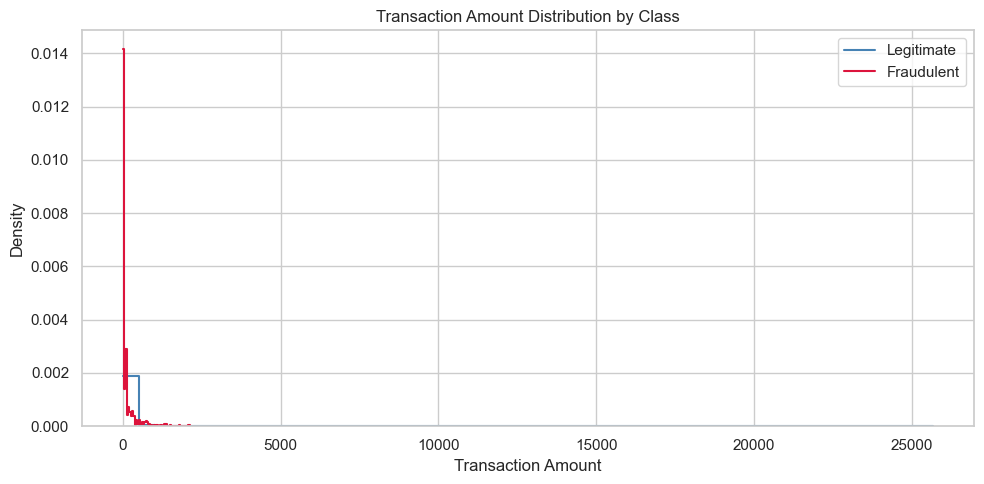

In [6]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df[df["Class"] == 0],
    x="Amount",
    bins=50,
    stat="density",
    color="steelblue",
    element="step",
    fill=False,
    label="Legitimate"
)

sns.histplot(
    data=df[df["Class"] == 1],
    x="Amount",
    bins=50,
    stat="density",
    color="crimson",
    element="step",
    fill=False,
    label="Fraudulent"
)

plt.title("Transaction Amount Distribution by Class")
plt.xlabel("Transaction Amount")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

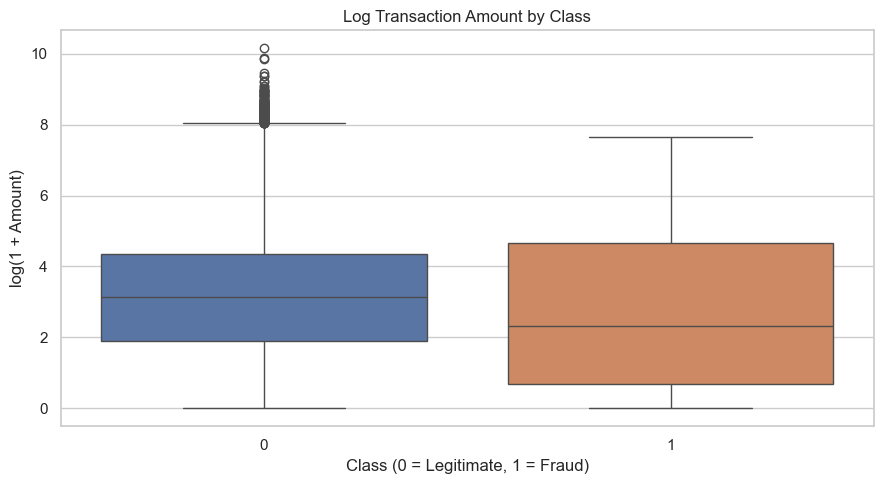

In [7]:
df["LogAmount"] = np.log1p(df["Amount"])

plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="Class", y="LogAmount", hue="Class", legend=False)

plt.title("Log Transaction Amount by Class")
plt.xlabel("Class (0 = Legitimate, 1 = Fraud)")
plt.ylabel("log(1 + Amount)")
plt.tight_layout()
plt.show()

,ElapsedHour,Transactions,FraudCases,FraudRate,FraudRatePercent
0,0,7695,6,0.0008,0.0780
1,1,4220,10,0.0024,0.2370
2,2,3328,57,0.0171,1.7127
3,3,3492,17,0.0049,0.4868
4,4,2209,23,0.0104,1.0412
5,5,2990,11,0.0037,0.3679
6,6,4101,9,0.0022,0.2195
7,7,7243,23,0.0032,0.3175
8,8,10276,9,0.0009,0.0876
9,9,15838,16,0.0010,0.1010


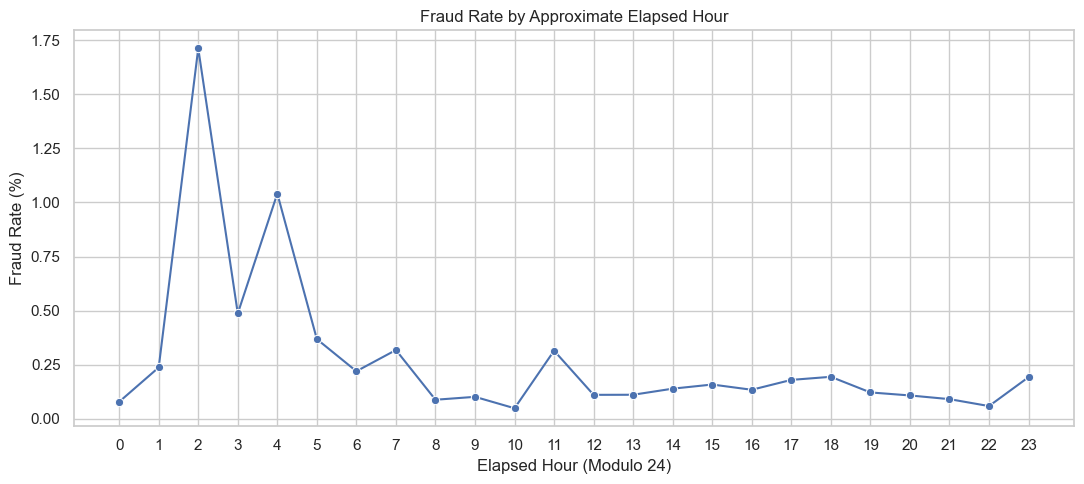

In [8]:
time_df = df[["Time", "Class"]].copy()

time_df["ElapsedHour"] = (
    (time_df["Time"] // 3600).astype(int) % 24
)

hourly_summary = (
    time_df.groupby("ElapsedHour")
    .agg(
        Transactions=("Class", "size"),
        FraudCases=("Class", "sum"),
        FraudRate=("Class", "mean")
    )
    .reset_index()
)

hourly_summary["FraudRatePercent"] = hourly_summary["FraudRate"] * 100

display(hourly_summary.round(4))

plt.figure(figsize=(11, 5))
sns.lineplot(
    data=hourly_summary,
    x="ElapsedHour",
    y="FraudRatePercent",
    marker="o"
)

plt.title("Fraud Rate by Approximate Elapsed Hour")
plt.xlabel("Elapsed Hour (Modulo 24)")
plt.ylabel("Fraud Rate (%)")
plt.xticks(range(24))
plt.tight_layout()
plt.show()

In [9]:
print("Amount summary by class:")
display(
    df.groupby("Class")["Amount"]
      .agg(["count", "mean", "median", "min", "max"])
      .round(2)
)

Amount summary by class:


,count,mean,median,min,max
Class,,,,,
0,284315,88.29,22.00,0.0,25691.16
1,492,122.21,9.25,0.0,2125.87


In [10]:
# Create a log-transformed transaction amount
model_df = df.copy()
model_df["LogAmount"] = np.log1p(model_df["Amount"])
model_df = model_df.drop(columns=["Amount"])

# Separate features and target
X = model_df.drop(columns=["Class"])
y = model_df["Class"]

# Stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nFraud percentage in training set:")
print(f"{y_train.mean() * 100:.4f}%")

print("\nFraud percentage in testing set:")
print(f"{y_test.mean() * 100:.4f}%")

print("\nTraining class counts:")
print(y_train.value_counts())

print("\nTesting class counts:")
print(y_test.value_counts())

Training set: (227845, 30)
Testing set: (56962, 30)

Fraud percentage in training set:
0.1729%

Fraud percentage in testing set:
0.1720%

Training class counts:
Class
0    227451
1       394
Name: count, dtype: int64

Testing class counts:
Class
0    56864
1       98
Name: count, dtype: int64


In [11]:
models = {
    "Logistic Regression": ImbPipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("smote", SMOTE(
            random_state=RANDOM_STATE,
            k_neighbors=5
        )),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=RANDOM_STATE
        ))
    ]),

    "Random Forest": ImbPipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("smote", SMOTE(
            random_state=RANDOM_STATE,
            k_neighbors=5
        )),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            max_depth=15,
            min_samples_leaf=2,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])
}

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)

print("Training completed.")

Training Logistic Regression...
Training Random Forest...
Training completed.


In [12]:
results = []
predictions = {}
probabilities = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    predictions[name] = y_pred
    probabilities[name] = y_prob

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_test, y_prob),
        "Average Precision": average_precision_score(y_test, y_prob)
    })

results_df = pd.DataFrame(results).set_index("Model")

display(results_df.round(4))

,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Average Precision
Model,,,,,,
Logistic Regression,0.9742,0.0581,0.9184,0.1093,0.9710,0.7215
Random Forest,0.9992,0.7119,0.8571,0.7778,0.9878,0.8490


In [13]:
for name in models:
    print(f"\n{'=' * 55}")
    print(name)
    print("=" * 55)

    print(classification_report(
        y_test,
        predictions[name],
        labels=[0, 1],
        target_names=["Legitimate", "Fraud"],
        zero_division=0
    ))


Logistic Regression
              precision    recall  f1-score   support

  Legitimate       1.00      0.97      0.99     56864
       Fraud       0.06      0.92      0.11        98

    accuracy                           0.97     56962
   macro avg       0.53      0.95      0.55     56962
weighted avg       1.00      0.97      0.99     56962


Random Forest
              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56864
       Fraud       0.71      0.86      0.78        98

    accuracy                           1.00     56962
   macro avg       0.86      0.93      0.89     56962
weighted avg       1.00      1.00      1.00     56962



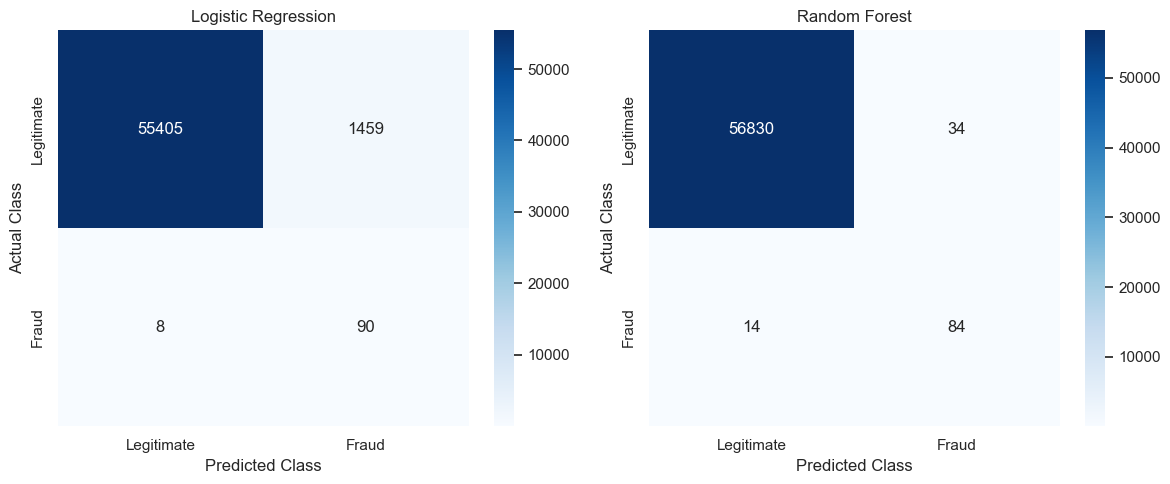

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, name in zip(axes, models):
    cm = confusion_matrix(
        y_test,
        predictions[name],
        labels=[0, 1]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Legitimate", "Fraud"],
        yticklabels=["Legitimate", "Fraud"],
        ax=ax
    )

    ax.set_title(name)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.tight_layout()
plt.show()

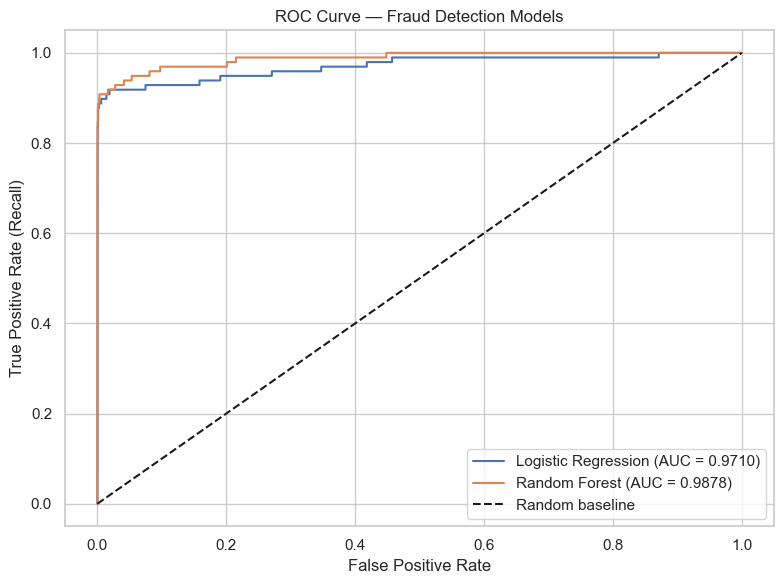

In [15]:
plt.figure(figsize=(8, 6))

for name in models:
    fpr, tpr, thresholds = roc_curve(
        y_test,
        probabilities[name]
    )

    auc_value = roc_auc_score(
        y_test,
        probabilities[name]
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc_value:.4f})"
    )

plt.plot([0, 1], [0, 1], "k--", label="Random baseline")

plt.title("ROC Curve — Fraud Detection Models")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.legend()
plt.tight_layout()
plt.show()

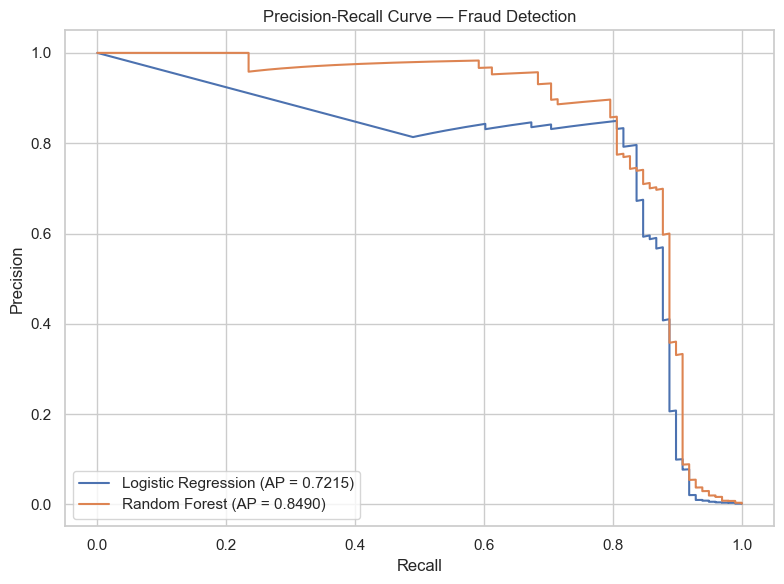

In [16]:
plt.figure(figsize=(8, 6))

for name in models:
    precision_values, recall_values, _ = precision_recall_curve(
        y_test,
        probabilities[name]
    )

    ap = average_precision_score(
        y_test,
        probabilities[name]
    )

    plt.plot(
        recall_values,
        precision_values,
        label=f"{name} (AP = {ap:.4f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve — Fraud Detection")
plt.legend()
plt.tight_layout()
plt.show()

Top 15 important features:


,Importance
V14,0.203277
V4,0.129323
V10,0.124670
V12,0.106215
V17,0.089614
V3,0.071378
V16,0.052206
V11,0.045344
V2,0.030763
V9,0.019897


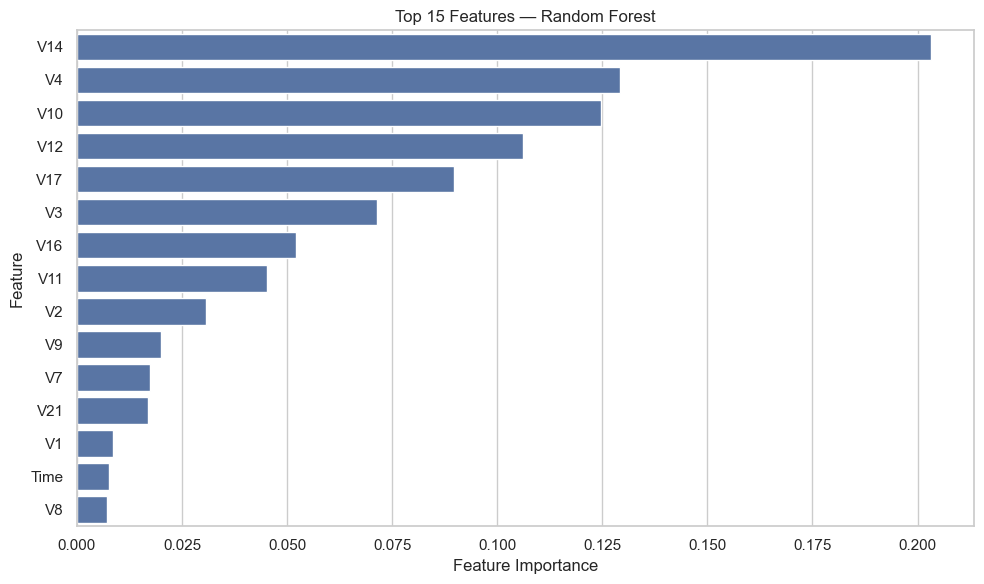

In [17]:
rf_model = models["Random Forest"].named_steps["classifier"]

feature_importance = pd.Series(
    rf_model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print("Top 15 important features:")
display(feature_importance.head(15).to_frame("Importance"))

plt.figure(figsize=(10, 6))

sns.barplot(
    x=feature_importance.head(15).values,
    y=feature_importance.head(15).index
)

plt.title("Top 15 Features — Random Forest")
plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

Features with the most negative coefficients:


,Coefficient
V10,-1.881767
V14,-1.498303
V12,-1.058898
V17,-0.985693
V8,-0.916918
V16,-0.898557
V9,-0.733633
V2,-0.627430
Time,-0.526955
V13,-0.509663


Features with the most positive coefficients:


,Coefficient
V4,1.811816
V1,1.118420
V11,0.530047
V5,0.482720
V22,0.393431
V21,0.259357
V7,0.243815
V28,0.201221
LogAmount,0.192509
V19,0.093477


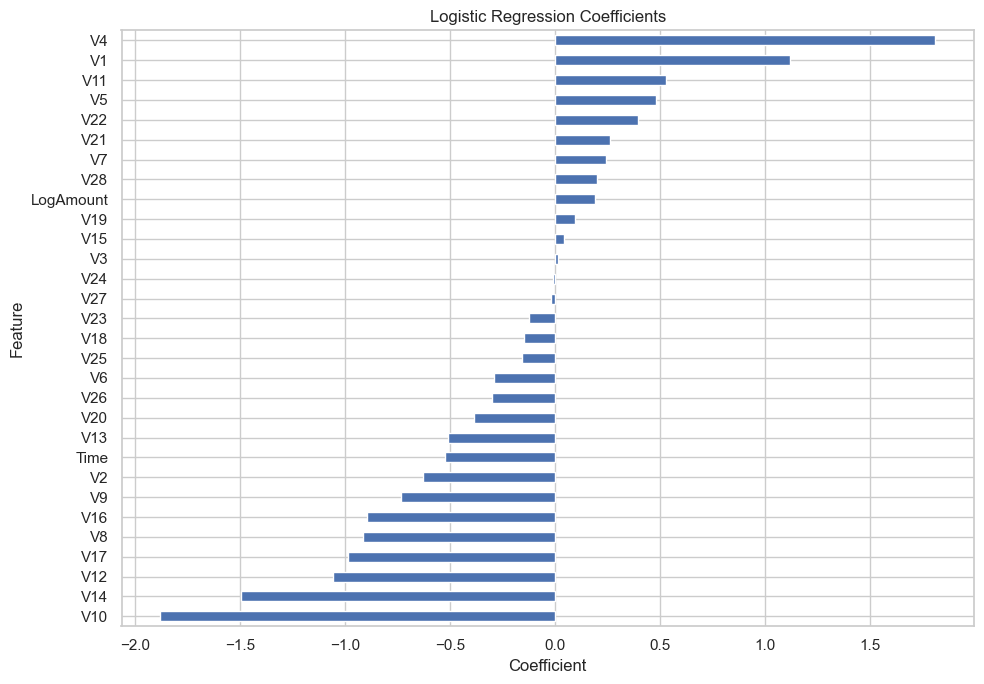

In [18]:
lr_model = models["Logistic Regression"].named_steps["classifier"]

coefficients = pd.Series(
    lr_model.coef_[0],
    index=X_train.columns
).sort_values()

print("Features with the most negative coefficients:")
display(coefficients.head(10).to_frame("Coefficient"))

print("Features with the most positive coefficients:")
display(coefficients.tail(10).sort_values(ascending=False).to_frame("Coefficient"))

plt.figure(figsize=(10, 7))

coefficients.sort_values().plot(kind="barh")

plt.title("Logistic Regression Coefficients")
plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [19]:
# Illustrative threshold analysis for the Random Forest
# Use a validation set for final threshold selection in a real workflow.

rf_probabilities = probabilities["Random Forest"]

threshold_results = []

for threshold in [0.10, 0.20, 0.30, 0.40, 0.50, 0.60, 0.70]:
    threshold_predictions = (
        rf_probabilities >= threshold
    ).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(
            y_test, threshold_predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, threshold_predictions, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, threshold_predictions, zero_division=0
        )
    })

display(pd.DataFrame(threshold_results).round(4))

,Threshold,Precision,Recall,F1-Score
0,0.1,0.1384,0.9082,0.2402
1,0.2,0.3296,0.9082,0.4837
2,0.3,0.4943,0.8878,0.6350
3,0.4,0.6099,0.8776,0.7197
4,0.5,0.7119,0.8571,0.7778
5,0.6,0.7500,0.8265,0.7864
6,0.7,0.7822,0.8061,0.7940


In [20]:
os.makedirs("outputs", exist_ok=True)

# Save metrics
results_df.to_csv("outputs/model_comparison.csv")

# Save predictions for review
prediction_output = pd.DataFrame({
    "Actual_Class": y_test.to_numpy()
})

for name in models:
    safe_name = name.lower().replace(" ", "_")

    prediction_output[f"{safe_name}_prediction"] = predictions[name]
    prediction_output[f"{safe_name}_probability"] = probabilities[name]

prediction_output.to_csv(
    "outputs/fraud_predictions.csv",
    index=False
)

# Save feature importance
feature_importance.to_csv(
    "outputs/random_forest_feature_importance.csv",
    header=["Importance"]
)

print("Output files saved in the outputs folder.")

Output files saved in the outputs folder.
